In [1]:
from transformers import pipeline, AutoModelForCausalLM, AutoTokenizer

In [2]:
import torch, time, gc, sys

In [3]:
def free_gpu(model):
    if model:
        del model
    torch.cuda.empty_cache()
    gc.collect()

In [4]:
def kv_cache_bytes(cache) -> int:
    """Real memory held by K/V tensors in past_key_values (bytes)."""
    if cache is None:
        return 0

    if hasattr(cache, "layers"):                  # transformers >= 4.56 (Cache.layers[i].keys/.values)
        tensors = []
        for layer in cache.layers:
            tensors += [getattr(layer, "keys", None), getattr(layer, "values", None)]
    elif hasattr(cache, "key_cache"):             # DynamicCache, ~4.36 – 4.55
        tensors = list(cache.key_cache) + list(cache.value_cache)
    else:                                         # legacy tuple(tuple(k, v), ...)
        tensors = [t for layer in cache for t in layer]

    seen, total = set(), 0
    for t in tensors:
        if isinstance(t, torch.Tensor) and t.numel() > 0:
            ptr = t.untyped_storage().data_ptr()   # dedupe layers that share KV (e.g. Gemma-3n)
            if ptr not in seen:
                seen.add(ptr)
                total += t.untyped_storage().nbytes()
    return total

In [5]:
model_path = "/srv/models/qwen2.5-0.5B"

In [6]:
tokenizer = AutoTokenizer.from_pretrained(model_path, trust_remote_code=True)

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [7]:
model = (
    AutoModelForCausalLM.from_pretrained(model_path, trust_remote_code=True).to("cuda" if torch.cuda.is_available else "cpu")
)

In [8]:
# prompt = "The history of human … … … How might the next wave of communication tools shape our relationships, societies, and sense of identity?"
prompt = "United States citizens have a bunch of benefits like"

In [9]:
num_iterations = 100

In [10]:
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(model.device)
idx = input_ids

In [11]:
start_time = total_time = time.time()
print(start_time)

1795546799.1136763


In [12]:
times_w_cache = []

In [13]:
past_key_values = None
for i in range(num_iterations):
    print(f"input_ids size: {str(input_ids.size())}")
    print(f"past_key_values size: {kv_cache_bytes(past_key_values) / 2**20:.2f} MiB")
    with torch.no_grad():
        outputs = model(
            input_ids,
            past_key_values=past_key_values,
            use_cache=True
        )
        logits = outputs.logits
        # UPDATE KV cache
        past_key_values = outputs.past_key_values
        torch.cuda.synchronize()
    # get only logits for the last token
    logits = logits[:, -1, :]
    # get probability distribution
    probas = torch.softmax(logits, dim=-1)
    # get the next token
    idx_next = torch.multinomial(probas, num_samples=1)
    # for the next run due to using KV cache we pass to the model only the last token
    input_ids = idx_next
    idx = torch.cat((idx, idx_next), dim=1)
    time_cost = time.time() - start_time
    times_w_cache.append(time_cost)
    if not i:
        print(f"Time taken to generate first token is: {time_cost:.4f} seconds")
    else:
        print(f"Time taken to generate {i} token is: {time_cost:.4f} seconds")
        
    start_time = time.time()
    # EOS - End Of Sequence
    if idx_next.item() == tokenizer.eos_token_id:
        print("\n[Generation completed - EOS token has been generated]")
        break
print(f"Total generation time is {time.time() - total_time:.4f} seconds")

input_ids size: torch.Size([1, 9])
past_key_values size: 0.00 MiB
Time taken to generate first token is: 0.1696 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.21 MiB
Time taken to generate 1 token is: 0.0229 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.23 MiB
Time taken to generate 2 token is: 0.0220 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.26 MiB
Time taken to generate 3 token is: 0.0213 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.28 MiB
Time taken to generate 4 token is: 0.0199 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.30 MiB
Time taken to generate 5 token is: 0.0196 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.33 MiB
Time taken to generate 6 token is: 0.0195 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.35 MiB
Time taken to generate 7 token is: 0.0197 seconds
input_ids size: torch.Size([1, 1])
past_key_values size: 0.38 MiB
Ti

In [14]:
generated_text = tokenizer.decode(idx[0], skip_special_tokens=True)
print(generated_text)
free_gpu(model=model)

United States citizens have a bunch of benefits like Medicare and must pay taxes to support them. There is one more benefit that they get, which you have not mentioned ( well me). Your available income is $2000, and your social safety net contribution for tax purposes is $1000.  What is your income tax liability? (Round to the nearest penny) To determine your income tax liability, we need to follow these steps:

1. **Identify your available sources of income:**
   - **Part 1


Text(0.5, 1.0, 'LLM Generation Times for each token')

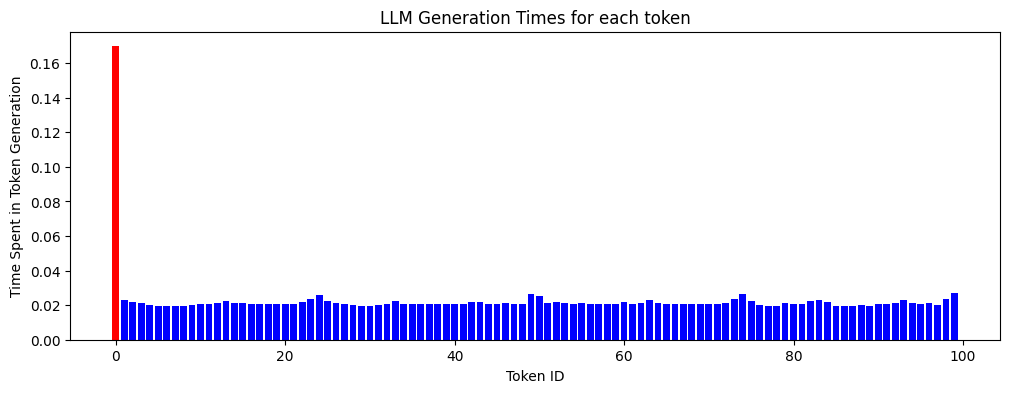

In [15]:
import matplotlib.pyplot as plt

# First chart: First bar red, others blue
plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
plt.bar(range(len(times_w_cache)), times_w_cache, color=['red'] + ['blue'] * (len(times_w_cache) - 1))
plt.xlabel("Token ID")
plt.ylabel("Time Spent in Token Generation")
plt.title("LLM Generation Times for each token")

# # Second chart: Exclude the first element
# plt.subplot(1, 2, 2)
# plt.bar(range(len(times) - 1), times[1:])
# plt.xlabel("Token ID")
# plt.ylabel("Time Spent in Token Generation")
# plt.title("Token Generation Times (Excluded the initial prompt tokens)")

# plt.tight_layout()
# plt.show()